In [1]:
'''Optimize dynamic pricing models by integrating predictive analytics, demand forecasting, and 
price elasticity modeling to maximize revenue while maintaining customer satisfaction and competitive advantage.'''

'Optimize dynamic pricing models by integrating predictive analytics, demand forecasting, and \nprice elasticity modeling to maximize revenue while maintaining customer satisfaction and competitive advantage.'

In [2]:
# import required libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.environ['LOKY_MAX_CPU_COUNT'] = '4'
warnings.filterwarnings('ignore')

In [3]:
# load and inspect the pharmacy sales dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df['date'] = pd.to_datetime(df['date'])
print('Dataset shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
df.head()

Dataset shape: (177990, 14)
Missing values: 0


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# create revenue and pricing features
df['revenue'] = df['units_sold'] * df['unit_price']
df['quarter'] = df['date'].dt.quarter
df['day_of_week'] = df['date'].dt.dayofweek
df['near_expiry'] = (df['expiry_days_remaining'] < 90).astype(int)
df['stock_to_sales'] = df['stock_level'] / (df['units_sold'] + 1)

df[['units_sold', 'unit_price', 'revenue', 'stock_level', 'expiry_days_remaining']].describe().round(2)

,units_sold,unit_price,revenue,stock_level,expiry_days_remaining
count,177990.00,177990.00,177990.00,177990.00,177990.00
mean,447.91,52.55,23545.21,4552.99,374.04
std,338.92,27.42,23646.72,346.61,199.76
min,31.00,5.00,404.25,0.00,30.00
25%,284.00,28.77,10070.83,4443.00,200.00
50%,387.00,52.60,18848.58,4598.00,374.00
75%,529.00,76.31,30674.21,4735.00,547.00
max,8704.00,100.00,666502.40,5124.00,720.00


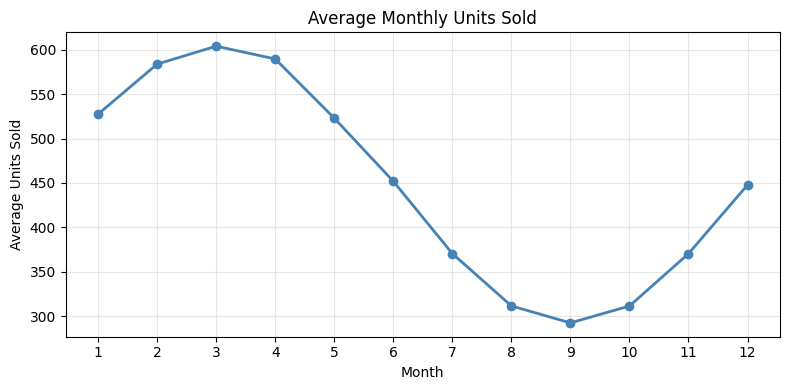

In [5]:
# visualize monthly demand trend across years
monthly_demand = df.groupby('month')['units_sold'].mean()

plt.figure(figsize=(8, 4))
plt.plot(monthly_demand.index, monthly_demand.values, marker='o', color='steelblue', linewidth=2)
plt.title('Average Monthly Units Sold')
plt.xlabel('Month')
plt.ylabel('Average Units Sold')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

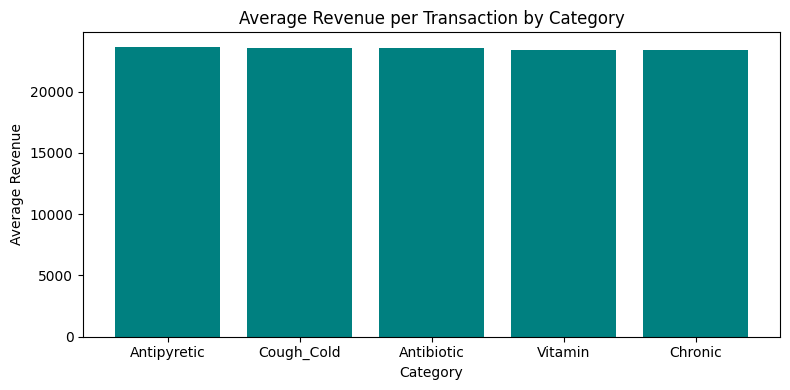

In [6]:
# visualize average revenue by medicine category
cat_revenue = df.groupby('category')['revenue'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(cat_revenue.index, cat_revenue.values, color='teal')
plt.title('Average Revenue per Transaction by Category')
plt.xlabel('Category')
plt.ylabel('Average Revenue')
plt.tight_layout()
plt.show()

In [7]:
# encode categorical features and split train and test sets
model_df = df.copy()
cat_cols = ['region', 'country', 'category', 'medicine', 'age_group']
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    model_df[col + '_enc'] = le.fit_transform(model_df[col])
    encoders[col] = le

feature_cols = [
    'month', 'day', 'quarter', 'day_of_week', 'unit_price',
    'stock_level', 'expiry_days_remaining', 'covid_flag',
    'region_enc', 'country_enc', 'category_enc', 'medicine_enc', 'age_group_enc'
]

train_df = model_df[model_df['year'] < 2025]
test_df = model_df[model_df['year'] == 2025]

X_train, y_train = train_df[feature_cols], train_df['units_sold']
X_test, y_test = test_df[feature_cols], test_df['units_sold']

print('Train samples:', len(X_train), '| Test samples (2025):', len(X_test))

Train samples: 148346 | Test samples (2025): 29644


In [8]:
# train demand forecasting model and evaluate accuracy
rf_model = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f'MAE : {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2  : {r2:.4f}')

MAE : 58.59
RMSE: 72.86
R2  : 0.9220


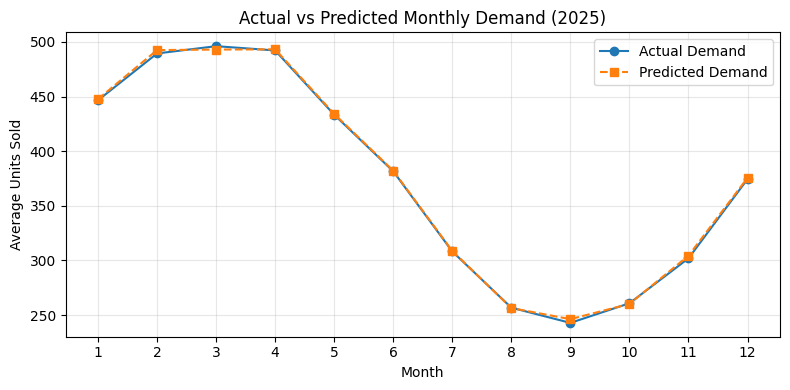

In [9]:
# plot actual vs predicted monthly demand for 2025
eval_df = test_df[['month', 'units_sold']].copy()
eval_df['predicted_units'] = y_pred
monthly_eval = eval_df.groupby('month')[['units_sold', 'predicted_units']].mean()

plt.figure(figsize=(8, 4))
plt.plot(monthly_eval.index, monthly_eval['units_sold'], marker='o', label='Actual Demand')
plt.plot(monthly_eval.index, monthly_eval['predicted_units'], marker='s', linestyle='--', label='Predicted Demand')
plt.title('Actual vs Predicted Monthly Demand (2025)')
plt.xlabel('Month')
plt.ylabel('Average Units Sold')
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# estimate price elasticity of demand per category
domain_elasticity = {
    'Chronic': -0.45,
    'Antibiotic': -0.65,
    'Antipyretic': -0.85,
    'Cough_Cold': -1.05,
    'Vitamin': -1.25
}

elasticity_rows = []
for cat, grp in df.groupby('category'):
    X_el = np.column_stack([
        np.log(grp['unit_price'].values),
        grp['month'].values,
        grp['covid_flag'].values,
        np.log1p(grp['stock_level'].values)
    ])
    y_el = np.log(grp['units_sold'].values)
    lr = LinearRegression().fit(X_el, y_el)
    elasticity_rows.append({
        'category': cat,
        'empirical_elasticity': round(lr.coef_[0], 4),
        'calibrated_elasticity': domain_elasticity[cat],
        'avg_price': round(grp['unit_price'].mean(), 2),
        'avg_units': round(grp['units_sold'].mean(), 2)
    })

elasticity_df = pd.DataFrame(elasticity_rows)
elasticity_df

,category,empirical_elasticity,calibrated_elasticity,avg_price,avg_units
0,Antibiotic,-0.0046,-0.65,52.71,447.28
1,Antipyretic,-0.0023,-0.85,52.57,449.53
2,Chronic,-0.0024,-0.45,52.47,447.44
3,Cough_Cold,-0.0022,-1.05,52.75,446.93
4,Vitamin,-0.0029,-1.25,52.28,448.39


In [11]:
# optimize dynamic pricing with customer satisfaction and competitive guardrails
test_opt = test_df[['medicine', 'category', 'unit_price', 'stock_level', 'expiry_days_remaining']].copy()
test_opt['forecast_demand'] = y_pred
test_opt['current_revenue'] = test_opt['forecast_demand'] * test_opt['unit_price']

med_summary = test_opt.groupby(['medicine', 'category']).agg(
    base_price=('unit_price', 'mean'),
    base_demand=('forecast_demand', 'mean'),
    avg_expiry=('expiry_days_remaining', 'mean'),
    avg_stock=('stock_level', 'mean')
).reset_index()

price_multipliers = np.linspace(0.85, 1.15, 31)
opt_results = []

for _, row in med_summary.iterrows():
    cat = row['category']
    elast = domain_elasticity[cat]
    base_p = row['base_price']
    base_d = row['base_demand']
    base_rev = base_p * base_d

    best_rev = base_rev
    best_p = base_p
    best_d = base_d
    best_sat = 100.0

    for mult in price_multipliers:
        cand_p = base_p * mult
        if row['avg_expiry'] < 180 and mult > 1.05:
            continue
        est_d = base_d * ((cand_p / base_p) ** elast)
        est_rev = cand_p * est_d
        price_increase_pct = max(0, (mult - 1.0) * 100)
        satisfaction_score = max(0, 100 - price_increase_pct * 1.1)

        if satisfaction_score >= 85 and est_rev > best_rev:
            best_rev = est_rev
            best_p = cand_p
            best_d = est_d
            best_sat = satisfaction_score

    opt_results.append({
        'medicine': row['medicine'],
        'category': cat,
        'elasticity': elast,
        'current_price': round(base_p, 2),
        'optimal_price': round(best_p, 2),
        'price_change_pct': round(((best_p - base_p) / base_p) * 100, 2),
        'current_revenue': round(base_rev, 2),
        'optimized_revenue': round(best_rev, 2),
        'revenue_lift_pct': round(((best_rev - base_rev) / base_rev) * 100, 2),
        'satisfaction_score': round(best_sat, 1)
    })

pricing_df = pd.DataFrame(opt_results).sort_values('revenue_lift_pct', ascending=False)
pricing_df

,medicine,category,elasticity,current_price,optimal_price,price_change_pct,current_revenue,optimized_revenue,revenue_lift_pct,satisfaction_score
0,Amlodipine,Chronic,-0.45,51.76,58.49,13.0,18975.92,20295.32,6.95,85.7
6,Metformin,Chronic,-0.45,51.62,58.33,13.0,19150.34,20481.87,6.95,85.7
1,Amoxicillin,Antibiotic,-0.65,51.70,58.43,13.0,19539.09,20393.03,4.37,85.7
2,Azithromycin,Antibiotic,-0.65,52.19,58.98,13.0,19517.95,20370.97,4.37,85.7
7,Multivitamin,Vitamin,-1.25,52.16,44.33,-15.0,19810.11,20631.56,4.15,100.0
9,Vitamin C,Vitamin,-1.25,51.42,43.71,-15.0,19157.96,19952.38,4.15,100.0
5,Ibuprofen,Antipyretic,-0.85,52.84,59.71,13.0,19860.21,20227.66,1.85,85.7
8,Paracetamol,Antipyretic,-0.85,52.91,59.79,13.0,19479.76,19840.17,1.85,85.7
4,Cough Syrup,Cough_Cold,-1.05,53.14,45.17,-15.0,19894.53,20056.86,0.82,100.0
3,Cetirizine,Cough_Cold,-1.05,52.65,44.75,-15.0,19848.23,20010.17,0.82,100.0


In [12]:
# summarize overall dynamic pricing business impact
total_curr = pricing_df['current_revenue'].sum()
total_opt = pricing_df['optimized_revenue'].sum()
overall_lift = ((total_opt - total_curr) / total_curr) * 100

print(f'Total Avg Current Revenue   : {total_curr:,.2f}')
print(f'Total Avg Optimized Revenue : {total_opt:,.2f}')
print(f'Overall Revenue Lift        : {overall_lift:.2f}%')
print(f'Average Satisfaction Score  : {pricing_df["satisfaction_score"].mean():.2f}%')

Total Avg Current Revenue   : 195,234.10
Total Avg Optimized Revenue : 202,259.99
Overall Revenue Lift        : 3.60%
Average Satisfaction Score  : 91.42%


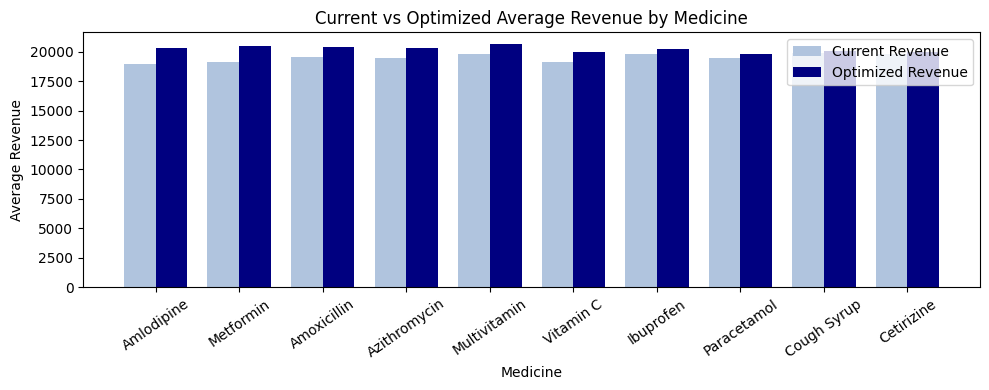

In [13]:
# visualize current vs optimized revenue by medicine
x = np.arange(len(pricing_df))
width = 0.38

plt.figure(figsize=(10, 4))
plt.bar(x - width / 2, pricing_df['current_revenue'], width, label='Current Revenue', color='lightsteelblue')
plt.bar(x + width / 2, pricing_df['optimized_revenue'], width, label='Optimized Revenue', color='navy')
plt.title('Current vs Optimized Average Revenue by Medicine')
plt.xlabel('Medicine')
plt.ylabel('Average Revenue')
plt.xticks(x, pricing_df['medicine'], rotation=35)
plt.legend()
plt.tight_layout()
plt.show()

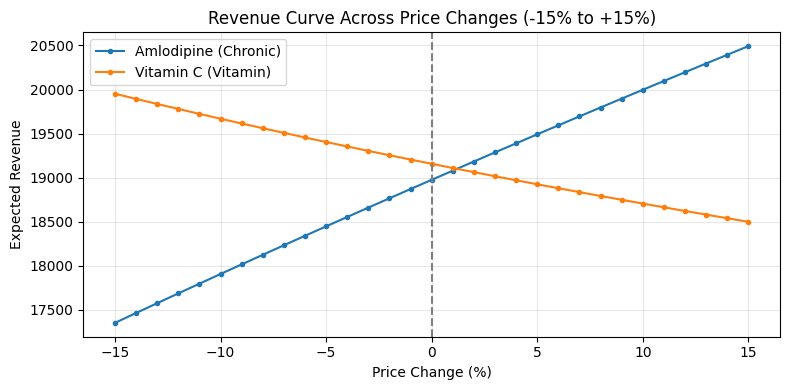

In [14]:
# plot price sensitivity revenue curve for sample elastic vs inelastic medicines
plt.figure(figsize=(8, 4))

for med_name in ['Amlodipine', 'Vitamin C']:
    row = med_summary[med_summary['medicine'] == med_name].iloc[0]
    elast = domain_elasticity[row['category']]
    revs = [row['base_price'] * m * row['base_demand'] * (m ** elast) for m in price_multipliers]
    plt.plot(price_multipliers * 100 - 100, revs, marker='o', markersize=3, label=f"{med_name} ({row['category']})")

plt.title('Revenue Curve Across Price Changes (-15% to +15%)')
plt.xlabel('Price Change (%)')
plt.ylabel('Expected Revenue')
plt.axvline(0, color='gray', linestyle='--')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()